# V-JEPA Decoder Post-Training & Transition Rollout Visualization

This notebook post-trains a `DecoderTransformer` on top of the **frozen** `FSQ_V_JEPA` encoder (`fsq_v_jepa_run_1`) using the DMC Walker dataset (`walker_trajs_h5`).

All directory conventions, config files, weight naming (`weights/decoder_5.78m.pt`), and train/test trajectory splits (`seed=42`, `split_ratio=0.9`) match `train_ae.py` so that `jepa_runs/fsq_v_jepa_run_1` becomes a drop-in counterpart to `ae_runs/fsq_videovae_run_1`.

In [1]:
import math
import os
import random
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import LambdaLR
from torch.utils.data import DataLoader
from torchvision.utils import save_image
from tqdm import tqdm

from rvsablation.ae import DecoderTransformer, FSQ_VideoVAE
from rvsablation.core import _TransformerStack
from rvsablation.jepa import FSQ_V_JEPA
from rvsablation.utils import (
    get_3d_sincos_pos_embed,
    get_dataset,
    patchify_clip,
    read_config,
    seed_everything,
    unpatchify_clip,
    write_config,
)

In [2]:
MODEL_TYPE = "jepa"
RUN_NAME = "fsq_v_jepa_run_1"
AE_RUN_NAME = "fsq_videovae_run_1"

RUN_DIR = Path("..") / f"{MODEL_TYPE}_runs" / RUN_NAME
WEIGHTS_DIR = RUN_DIR / "weights"
CONFS_DIR = RUN_DIR / "confs"
OUTPUTS_DIR = RUN_DIR / "training_outputs"

AE_DECODER_CONF_PATH = Path("..") / "ae_runs" / AE_RUN_NAME / "confs" / "decoder_config.json"

os.makedirs(WEIGHTS_DIR, exist_ok=True)
os.makedirs(CONFS_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

# HYPERPARAMETERS (aligned with train_ae.py)
EPOCHS = 100
WARMUP_EPOCHS = 5
BATCH_SIZE = 350
LR = 2e-4
SEED = 42

# DATASET PARAMETERS (matches fsq_v_jepa_run_1 / fsq_videovae_run_1 split)
DATA_PATH = "../data/walker_trajs_h5/data.h5"
DATA_NUM_TRAJ = 25000
DATA_NUM_FRAMES = 100
SAMPLE_NUM_FRAMES = 8
SAMPLE_NUM_CLIPS = 12

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"🚀 Using device: {DEVICE}")

🚀 Using device: cuda


## 1. Dataset & Frozen V-JEPA Encoder Setup

We use `seed=42` with `get_dataset` so the $90/10$ trajectory split matches the original pretraining split (`22,500` training trajectories, `2,500` test trajectories).

In [5]:
rng = seed_everything(seed=SEED)

dataset, testset, *_ = get_dataset(
    rng=rng,
    root=DATA_PATH,
    sample_num_frames=SAMPLE_NUM_FRAMES,
    sample_num_clips=SAMPLE_NUM_CLIPS,
    data_num_traj=DATA_NUM_TRAJ,
    data_num_frames=DATA_NUM_FRAMES,
    dataset="walker",
)

dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=(DEVICE == "cuda"))
testloader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=(DEVICE == "cuda"))

print(f"📁 Loaded Walker dataset | Train clips: {len(dataset):,} | Test clips: {len(testset):,}")

🌱 Global seed set to 42
📁 Loaded Walker dataset | Train clips: 270,000 | Test clips: 30,000


In [6]:
# Load frozen FSQ-V-JEPA encoder
model_config = read_config(CONFS_DIR / "model_config.json")
model = FSQ_V_JEPA(**model_config)

encoder_weights_path = WEIGHTS_DIR / "model_4.9m.pt"
load_status = model.load_state_dict(torch.load(encoder_weights_path, map_location=DEVICE, weights_only=True))
print(f"⚙️ Loaded V-JEPA encoder ({encoder_weights_path.name}): {load_status}")

model = model.to(DEVICE).eval()
for param in model.parameters():
    param.requires_grad_(False)

# Initialize DecoderTransformer with the same architecture as FSQ_VideoVAE
decoder_config = read_config(AE_DECODER_CONF_PATH)
decoder = DecoderTransformer(
    spatial_grid_size=model.encoder.spatial_grid_size,
    temporal_grid_size=model.encoder.temporal_grid_size,
    input_dim=model_config["fsq_dim"],
    output_dim=model.encoder.tubelet_dim,
    **decoder_config,
).to(DEVICE)

dec_p_count = sum(p.numel() for p in decoder.parameters() if p.requires_grad)
dp_count = dec_p_count / 1_000_000
print(f"🧱 Initialized DecoderTransformer with {dec_p_count:,} trainable parameters ({dp_count:.2f}M).")

⚙️ Loaded V-JEPA encoder (model_4.9m.pt): <All keys matched successfully>
🧱 Initialized DecoderTransformer with 5,781,312 trainable parameters (5.78M).


## 2. Training & Evaluation Functions

Following `train_ae.py`, the target is the patchified video clip `patchify_clip(X, tubelet_size, patch_size)` optimized with MSE loss under `bfloat16` mixed precision, AdamW (`weight_decay=0.05` on non-norm/non-bias weights), and cosine learning rate decay with linear warmup.

In [7]:
def _lr_lambda(epoch, total_epochs, warmup_epochs):
    if epoch < warmup_epochs:
        return epoch / warmup_epochs
    progress = (epoch - warmup_epochs) / max(1, total_epochs - warmup_epochs)
    return 0.5 * (1.0 + math.cos(math.pi * progress))


def _train_epoch(
    model: FSQ_V_JEPA,
    decoder: DecoderTransformer,
    dataloader: DataLoader,
    optimizer: optim.AdamW,
    device: str,
):
    decoder.train()
    epoch_loss = 0.0

    bar = tqdm(enumerate(dataloader), desc="Training", total=len(dataloader), leave=False)
    for _, (X, *_) in bar:
        optimizer.zero_grad(set_to_none=True)
        X = X.to(device, non_blocking=True)

        with torch.no_grad(), torch.autocast(device, dtype=torch.bfloat16):
            target_X = patchify_clip(
                X,
                tubelet_size=model.encoder.tubelet_size,
                patch_size=model.encoder.patch_size,
            )
            Z = model(X)

        with torch.autocast(device, dtype=torch.bfloat16):
            pred_X = decoder(Z)
            loss = F.mse_loss(pred_X, target_X)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    return epoch_loss / len(dataloader)


@torch.no_grad()
def _eval_epoch(
    model: FSQ_V_JEPA,
    decoder: DecoderTransformer,
    dataloader: DataLoader,
    device: str,
):
    decoder.eval()
    epoch_loss = 0.0

    bar = tqdm(enumerate(dataloader), desc=" ↪Eval.", total=len(dataloader), leave=False)
    for _, (X, *_) in bar:
        X = X.to(device, non_blocking=True)

        with torch.autocast(device, dtype=torch.bfloat16):
            target_X = patchify_clip(
                X,
                tubelet_size=model.encoder.tubelet_size,
                patch_size=model.encoder.patch_size,
            )
            Z = model(X)
            pred_X = decoder(Z)
            loss = F.mse_loss(pred_X, target_X)

        epoch_loss += loss.item()

    random_idx = random.randint(0, pred_X.shape[0] - 1)
    save_x = pred_X[random_idx].unsqueeze(0).float().cpu()
    save_x = unpatchify_clip(
        save_x,
        duration=model.encoder.duration,
        tubelet_size=model.encoder.tubelet_size,
        image_size=model.encoder.image_size,
        patch_size=model.encoder.patch_size,
    ).clamp(0.0, 1.0)

    return epoch_loss / len(dataloader), save_x.squeeze(0)

In [8]:
# Parameter groups for weight decay (matching train_ae.py)
decay_params = []
no_decay_params = []
for name, param in decoder.named_parameters(prefix="decoder"):
    if not param.requires_grad:
        continue
    if name.endswith(".bias") or "norm" in name.lower():
        no_decay_params.append(param)
    else:
        decay_params.append(param)

trainable_params = [
    {"params": decay_params, "weight_decay": 0.05},
    {"params": no_decay_params, "weight_decay": 0.0},
]

optimizer = optim.AdamW(trainable_params, lr=LR, betas=(0.9, 0.95))
scheduler = LambdaLR(
    optimizer=optimizer,
    lr_lambda=partial(_lr_lambda, total_epochs=EPOCHS, warmup_epochs=WARMUP_EPOCHS),
)

decoder_weights_path = WEIGHTS_DIR / f"decoder_{dp_count:.2f}m.pt"

train_losses, eval_losses = [], []

print(f"--- Starting Decoder Post-Training for {RUN_NAME} ---")
for epoch in range(1, EPOCHS + 1):
    avg_loss = _train_epoch(
        model=model,
        decoder=decoder,
        dataloader=dataloader,
        optimizer=optimizer,
        device=DEVICE,
    )
    train_losses.append(avg_loss)
    current_lr = scheduler.get_last_lr()[0]
    print(f"Epoch: [{epoch:03d}/{EPOCHS}] | Train MSE: {avg_loss:.4f} | LR: {current_lr:.6f}")
    scheduler.step()

    if epoch % 10 == 0 or epoch == 1:
        avg_eval_loss, save_x = _eval_epoch(
            model=model,
            decoder=decoder,
            dataloader=testloader,
            device=DEVICE,
        )
        eval_losses.append((epoch, avg_eval_loss))
        save_image(save_x, OUTPUTS_DIR / f"epoch_{epoch}.png", nrow=model_config["duration"])
        print(f" ↪Eval. MSE: {avg_eval_loss:.4f}")

# Save final weights and decoder config using exact repo conventions
torch.save(decoder.state_dict(), decoder_weights_path)
write_config(CONFS_DIR / "decoder_config.json", decoder_config)

print(f"✅ Post-Training Complete! Final decoder saved to {decoder_weights_path}")

--- Starting Decoder Post-Training for fsq_v_jepa_run_1 ---


Epoch: [001/100] | Train MSE: 0.1368 | LR: 0.000000


 ↪Eval. MSE: 0.1368


Epoch: [002/100] | Train MSE: 0.0154 | LR: 0.000040


Epoch: [003/100] | Train MSE: 0.0096 | LR: 0.000080


Epoch: [004/100] | Train MSE: 0.0085 | LR: 0.000120


... (102 outputs left out)

Epoch: [098/100] | Train MSE: 0.0025 | LR: 0.000000


Epoch: [099/100] | Train MSE: 0.0025 | LR: 0.000000


Epoch: [100/100] | Train MSE: 0.0025 | LR: 0.000000


 ↪Eval. MSE: 0.0034
✅ Post-Training Complete! Final decoder saved to ../jepa_runs/fsq_v_jepa_run_1/weights/decoder_5.78m.pt


## 3. Visualizing Reconstructions & Transitions (AE vs. V-JEPA)

Once the V-JEPA decoder is trained, we can load both `fsq_videovae_run_1` and `fsq_v_jepa_run_1` along with their `WindowTransitionProbe` models (`transition_window/transition_window_best.pt`) and compare:
1. **Static reconstruction**: $\hat{X}_A = \text{Decoder}(\text{Encoder}(X_A))$
2. **1-step latent transition**: $\hat{X}_B = \text{Decoder}(\text{Transition}(\text{Encoder}(X_A), a_A))$
3. **Multi-step open-loop rollout**: Iteratively applying $\hat{Z}_{k} = \text{Transition}(\hat{Z}_{k-1}, a_{k-1})$ across a trajectory and decoding back to pixel space.

In [3]:
class WindowTransitionProbe(nn.Module):
    def __init__(
        self,
        spatial_grid_size,
        temporal_grid_size,
        latent_dim,
        action_dim,
        hidden_dim,
        depth,
        attention_dim,
        attention_num_heads,
    ):
        super().__init__()
        self.latent_proj = nn.Linear(latent_dim, hidden_dim, bias=False)
        self.action_proj = nn.Linear(action_dim, hidden_dim, bias=False)
        self.out_proj = nn.Linear(hidden_dim, latent_dim, bias=False)
        self.stack = _TransformerStack(hidden_dim, depth, attention_dim, attention_num_heads)
        pos = get_3d_sincos_pos_embed(hidden_dim, temporal_grid_size, spatial_grid_size)
        self.register_buffer("pos", pos.unsqueeze(0), persistent=False)

    def forward(self, x, action):
        x = self.latent_proj(x)
        action = self.action_proj(action).unsqueeze(1)
        return self.out_proj(self.stack(x + action + self.pos, attn_mask=None))


def load_visual_pipeline(model_type: str, run_name: str, action_dim: int = 6):
    run_dir = Path("..") / f"{model_type}_runs" / run_name
    m_cfg = read_config(run_dir / "confs" / "model_config.json")
    d_cfg = read_config(run_dir / "confs" / "decoder_config.json")

    encoder_cls = FSQ_VideoVAE if model_type == "ae" else FSQ_V_JEPA
    enc = encoder_cls(**m_cfg).to(DEVICE).eval()
    enc.load_state_dict(torch.load(run_dir / "weights" / "model_4.9m.pt", map_location=DEVICE, weights_only=True))

    dec = DecoderTransformer(
        spatial_grid_size=enc.encoder.spatial_grid_size,
        temporal_grid_size=enc.encoder.temporal_grid_size,
        input_dim=m_cfg["fsq_dim"],
        output_dim=enc.encoder.tubelet_dim,
        **d_cfg,
    ).to(DEVICE).eval()
    dec.load_state_dict(torch.load(run_dir / "weights" / "decoder_5.78m.pt", map_location=DEVICE, weights_only=True))

    trans = WindowTransitionProbe(
        spatial_grid_size=enc.encoder.spatial_grid_size,
        temporal_grid_size=enc.encoder.temporal_grid_size,
        latent_dim=m_cfg["fsq_dim"],
        action_dim=action_dim,
        hidden_dim=384,
        depth=6,
        attention_dim=384,
        attention_num_heads=6,
    ).to(DEVICE).eval()
    trans.load_state_dict(
        torch.load(run_dir / "transition_window" / "transition_window_best.pt", map_location=DEVICE, weights_only=True)
    )

    return enc, dec, trans


@torch.no_grad()
def decode_latents(decoder: DecoderTransformer, encoder_module, z: torch.Tensor) -> torch.Tensor:
    """Decode latent tokens (B, N, D) -> video tensor (B, T, C, H, W) clamped to [0, 1]."""
    patched_pred = decoder(z)
    return unpatchify_clip(
        patched_pred,
        duration=encoder_module.encoder.duration,
        tubelet_size=encoder_module.encoder.tubelet_size,
        image_size=encoder_module.encoder.image_size,
        patch_size=encoder_module.encoder.patch_size,
    ).clamp(0.0, 1.0)

🌱 Global seed set to 42


findfont: Failed to find font weight semibold, now using 700.


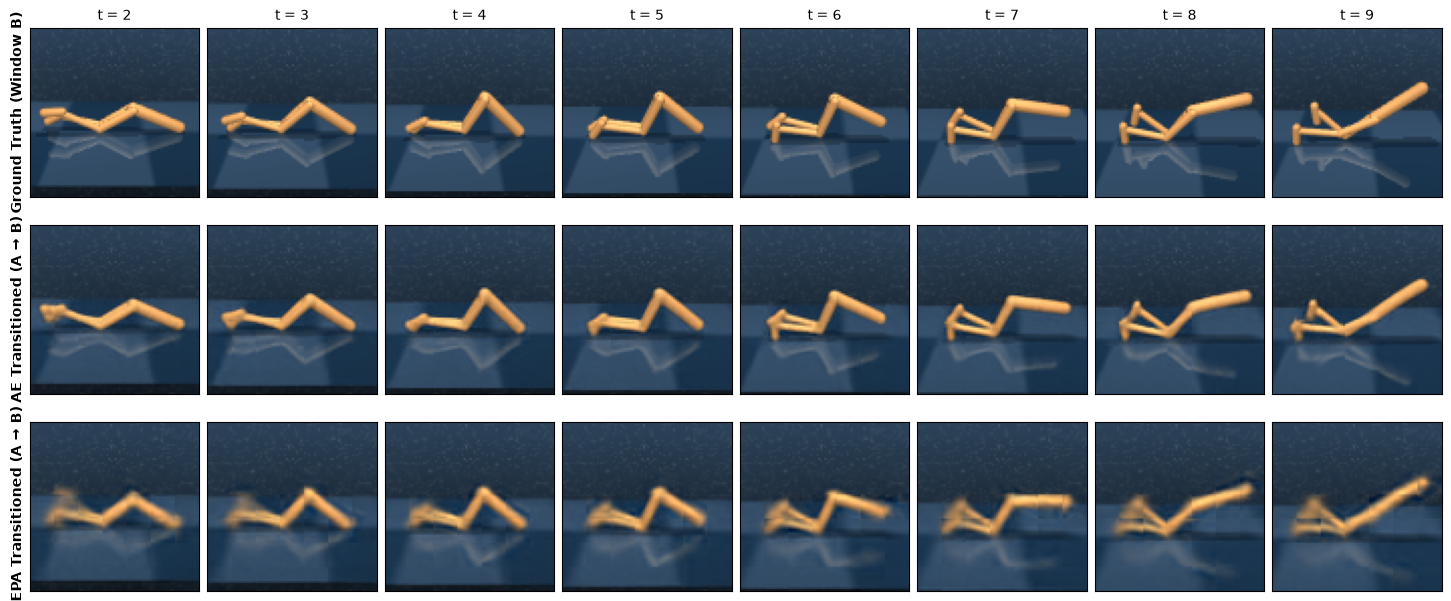

In [4]:
# Load 10-frame test clips to inspect 1-step transition (Window A: frames[:-2] -> Window B: frames[2:])
_, eval_10f_testset, _, _ = get_dataset(
    rng=seed_everything(SEED),
    root=DATA_PATH,
    sample_num_frames=10,
    sample_num_clips=12,
    data_num_traj=DATA_NUM_TRAJ,
    data_num_frames=DATA_NUM_FRAMES,
    dataset="walker",
)

sample_frames, sample_actions, *_ = eval_10f_testset[0]
pipelines = {
    "ae": load_visual_pipeline("ae", AE_RUN_NAME, action_dim=sample_actions.shape[-1]),
    "jepa": load_visual_pipeline("jepa", RUN_NAME, action_dim=sample_actions.shape[-1]),
}

@torch.no_grad()
def visualize_single_step_transition(sample_idx: int = 0, round_transition_latents: bool = False):
    frames, actions, *_ = eval_10f_testset[sample_idx]
    frames_a = frames[:-2].unsqueeze(0).to(DEVICE)  # (1, 8, C, H, W)
    frames_b = frames[2:].unsqueeze(0).to(DEVICE)   # (1, 8, C, H, W)
    action_a = actions[:-2][-1].unsqueeze(0).to(DEVICE, dtype=torch.float32)

    rows = [("Ground Truth (Window B)", frames_b[0].cpu())]
    for name in ("ae", "jepa"):
        enc, dec, trans = pipelines[name]
        z_a = enc(frames_a)
        z_b_pred = trans(z_a, action_a)
        if round_transition_latents:
            z_b_pred = z_b_pred.round()
        recon_b = decode_latents(dec, enc, z_b_pred)[0].cpu()
        rows.append((f"{name.upper()} Transitioned (A → B)", recon_b))

    num_frames = frames_b.shape[1]
    fig, axs = plt.subplots(len(rows), num_frames, figsize=(1.8 * num_frames, 2.0 * len(rows)), layout="constrained")
    for r_idx, (label, clip) in enumerate(rows):
        for t_idx in range(num_frames):
            ax = axs[r_idx, t_idx]
            ax.imshow(clip[t_idx].permute(1, 2, 0).numpy())
            ax.set_xticks([])
            ax.set_yticks([])
            if r_idx == 0:
                ax.set_title(f"t = {t_idx + 2}", fontsize=10)
            if t_idx == 0:
                ax.set_ylabel(label, fontsize=10, fontweight="semibold")
    plt.show()
    return fig


fig_step = visualize_single_step_transition(sample_idx=0)

In [25]:
rng=seed_everything(3452)

🌱 Global seed set to 3452


2332


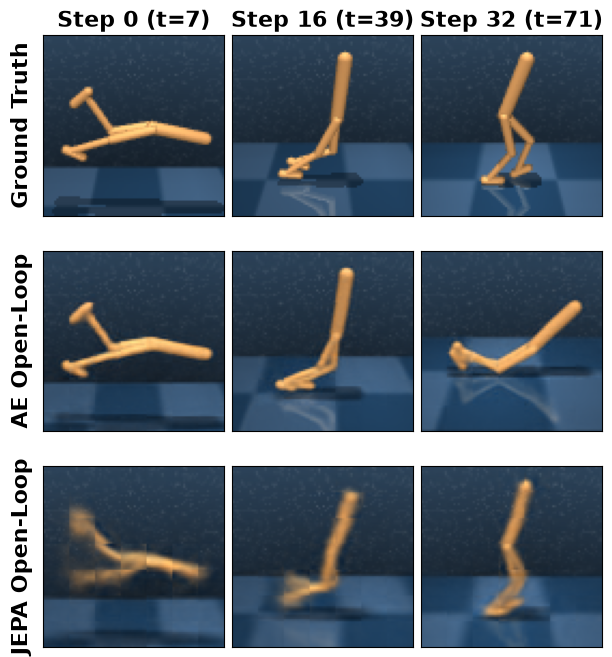

In [41]:
# Multi-step open-loop rollout visualization across a full trajectory (matching window_state_rollout_probe.ipynb)
_, traj_testset, _, _ = get_dataset(
    rng=rng,
    root=DATA_PATH,
    sample_num_frames=100,
    sample_num_clips=1,
    data_num_traj=DATA_NUM_TRAJ,
    data_num_frames=DATA_NUM_FRAMES,
    dataset="walker",
)

@torch.no_grad()
def visualize_open_loop_rollout(
    traj_idx: int = 0,
    horizon: int = 32,
    num_images: int = 9,
    round_latents: bool = False,
    title_fontsize: int = 15,
    label_fontsize: int = 16,
):
    """Roll out the transition model open-loop up to `horizon` steps and plot `num_images` evenly spaced steps."""
    frames, actions, *_ = traj_testset[traj_idx]
    num_frames_clip = SAMPLE_NUM_FRAMES  # 8
    tubelet_size = 2

    all_windows = torch.arange(frames.size(0)).unfold(0, num_frames_clip, tubelet_size)
    effective_horizon = min(horizon, all_windows.size(0) - 1)
    window_index = all_windows[: effective_horizon + 1]
    gt_windows = frames[window_index].to(DEVICE)  # (H+1, 8, C, H, W)
    departing_actions = actions[window_index][:-1, -1].to(DEVICE, dtype=torch.float32)

    n_imgs = min(max(1, num_images), effective_horizon + 1)
    if n_imgs == 1:
        step_indices = [0]
    else:
        step_indices = [(i * effective_horizon) // (n_imgs - 1) for i in range(n_imgs)]
    selected_steps = set(step_indices)

    # Display the last frame of each selected sliding window (t = 7 + 2 * step)
    gt_lead_frames = gt_windows[step_indices, -1].cpu()
    rows = [("Ground Truth", gt_lead_frames)]

    for name in ("ae", "jepa"):
        enc, dec, trans = pipelines[name]
        state = enc(gt_windows[0:1]).float()
        decoded_lead_frames = [decode_latents(dec, enc, state)[0, -1].cpu()]

        for step_idx, action in enumerate(departing_actions, start=1):
            state = trans(state, action.unsqueeze(0))
            if round_latents:
                state = state.round()
            if step_idx in selected_steps:
                decoded_window = decode_latents(dec, enc, state)
                decoded_lead_frames.append(decoded_window[0, -1].cpu())

        rows.append((f"{name.upper()} Open-Loop", torch.stack(decoded_lead_frames)))

    num_cols = len(step_indices)
    fig, axs = plt.subplots(
        len(rows), num_cols, figsize=(2.0 * num_cols, 2.2 * len(rows)), layout="constrained", squeeze=False
    )
    for r_idx, (label, seq) in enumerate(rows):
        for c_idx, step_idx in enumerate(step_indices):
            ax = axs[r_idx, c_idx]
            ax.imshow(seq[c_idx].permute(1, 2, 0).numpy())
            ax.set_xticks([])
            ax.set_yticks([])
            if r_idx == 0:
                frame_t = num_frames_clip - 1 + step_idx * tubelet_size
                ax.set_title(f"Step {step_idx} (t={frame_t})", fontsize=title_fontsize, fontweight="semibold", pad=6)
            if c_idx == 0:
                ax.set_ylabel(label, fontsize=label_fontsize, fontweight="semibold", labelpad=8)
    plt.show()
    return fig



ix = random.randint(0, len(traj_testset) - 1)
print(ix)
fig_rollout = visualize_open_loop_rollout(traj_idx=ix, 
                                          horizon=32, 
                                          num_images=3, 
                                          round_latents=False,
                                          title_fontsize=16)

In [17]:
fig_rollout.savefig("../pics/open_loop_decoded_mini_3.pdf", format="pdf", bbox_inches="tight")